## Quantiles, Outliers, and Robust Statistics

### Learning Goals
* Interpret percentiles and quartiles to understand data distributions beyond the center.
* Apply the Interquartile Range (IQR) rule to systematically detect potential outliers.
* Distinguish between unusual data values (genuine extremes) and erroneous data (mistakes).

---

### 1. Quantiles and Percentiles

Quantiles divide a rank-ordered dataset into equal-sized subsets. Common examples include quartiles (dividing data into 4 parts: $Q_1, Q_2, Q_3$) and percentiles (dividing data into 100 parts).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Sample waiting times in minutes
wait_minutes = np.array([3, 4, 4, 5, 5, 6, 7, 8, 9, 12, 15, 42])

# Calculate key percentiles
for p in [25, 50, 75, 90]:
    print(f"{p}th percentile: {np.percentile(wait_minutes, p):.2f}")

25th percentile: 4.75
50th percentile: 6.50
75th percentile: 9.75
90th percentile: 14.70


### 2. The IQR Outlier Rule

The Interquartile Range ($\text{IQR} = Q_3 - Q_1$) measures the spread of the middle 50% of the data and is robust to outliers. The standard boxplot convention flags values as potential outliers if they fall outside the inner fences:
$$
\text{Lower Fence} = Q_1 - 1.5 \times \text{IQR}
$$
$$
\text{Upper Fence} = Q_3 + 1.5 \times \text{IQR}
$$

In [2]:
# Compute IQR and outlier fences
q1, q3 = np.percentile(wait_minutes, [25, 75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

outliers = wait_minutes[(wait_minutes < lower) | (wait_minutes > upper)]

print(f"Fences: [{lower:.2f}, {upper:.2f}]")
print(f"Flagged values: {outliers}")

Fences: [-2.75, 17.25]
Flagged values: [42]


### 3. Visualization

Visualizing the distribution using a boxplot helps instantly reveal the median, spread of the middle 50%, and any values flagged beyond the whiskers.

/tmp/ipykernel_4332/2427164413.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(wait_minutes, vert=False, patch_artist=True, boxprops=dict(facecolor='lightblue'))


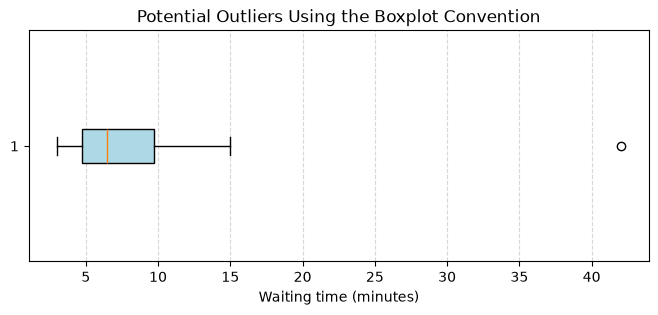

In [3]:
# Visualize potential outliers using a boxplot
plt.figure(figsize=(8, 3))
plt.boxplot(wait_minutes, vert=False, patch_artist=True, boxprops=dict(facecolor='lightblue'))
plt.xlabel("Waiting time (minutes)")
plt.title("Potential Outliers Using the Boxplot Convention")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.show()

> **Important Caution:** The IQR rule flags values *for investigation*; it does not automatically prove they are data entry errors. An extreme value (such as a 42-minute wait time) may represent a rare, genuine event that is critical to understand rather than discard.

---

### Exercises

Try each problem before running the answer-checking code below:

1. Find $Q_1$, the median ($Q_2$), $Q_3$, and the IQR for the dataset $[1, 2, 3, 4, 5, 6, 7, 20]$.
2. Explain why outliers should never be deleted automatically without domain context.
3. Give a practical example where the 90th percentile is far more useful than the mean.

In [4]:
import numpy as np

# --- Exercise 1 Verification ---
data_ex1 = np.array([1, 2, 3, 4, 5, 6, 7, 20])
q1_ex1, median_ex1, q3_ex1 = np.percentile(data_ex1, [25, 50, 75])
iqr_ex1 = q3_ex1 - q1_ex1

print(f"=== Exercise 1 Results ===")
print(f"Q1 (25th percentile): {q1_ex1:.2f}")
print(f"Median (50th percentile): {median_ex1:.2f}")
print(f"Q3 (75th percentile): {q3_ex1:.2f}")
print(f"IQR: {iqr_ex1:.2f}")

# --- Exercise 2 & 3 Conceptual Checks ---
print(f"\n=== Exercise 2: Outlier Deletion ===")
print("Outliers should not be deleted automatically because they often represent")
print("valuable, genuine extreme events (e.g., rare financial fraud, peak server traffic).")

print(f"\n=== Exercise 3: Percentile vs. Mean Use Case ===")
print("Example: Network latency or cloud server response times. System administrators")
print("care deeply about the 90th or 99th percentile (tail latency) to ensure SLAs are met")
print("for nearly all users, whereas a low mean can mask severe lag spikes experienced by a minority.")

=== Exercise 1 Results ===
Q1 (25th percentile): 2.75
Median (50th percentile): 4.50
Q3 (75th percentile): 6.25
IQR: 3.50

=== Exercise 2: Outlier Deletion ===
Outliers should not be deleted automatically because they often represent
valuable, genuine extreme events (e.g., rare financial fraud, peak server traffic).

=== Exercise 3: Percentile vs. Mean Use Case ===
Example: Network latency or cloud server response times. System administrators
care deeply about the 90th or 99th percentile (tail latency) to ensure SLAs are met
for nearly all users, whereas a low mean can mask severe lag spikes experienced by a minority.
